# Fixing an overconfident classifier with temperature scaling

Fix an overconfident image classifier after training, with a single parameter.

When a well-calibrated classifier says "95% sure", it is right 95% of the time. Modern networks
trained to convergence are often **overconfident**: they say 95% but are right less often.

**Temperature scaling** fixes this after training by dividing the network's logits (its outputs
before the softmax) by a single number, the temperature `T`:

- `T > 1` softens the probabilities (less confident);
- the predicted class never changes, only how confident the prediction is.

`T` is fitted on held-out data, with
[`TemperatureScaling`](https://anas-rz.github.io/keras-proba/api/postprocessing/#keras_proba.postprocessing.TemperatureScaling).

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist): 10 classes of clothing.
10,000 training images are held out to fit the temperature.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

keras.utils.set_random_seed(0)
(x, y), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x, x_test = x[..., None].astype("float32") / 255, x_test[..., None].astype("float32") / 255
x_val, y_val, x_train, y_train = x[:10_000], y[:10_000], x[10_000:], y[10_000:]

## Train a classifier until it is overconfident

A small CNN, trained for long enough to become overconfident. It outputs logits.

In [3]:
model = keras.Sequential(
    [
        keras.Input((28, 28, 1)),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(10),
    ]
)
model.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
model.fit(x_train, y_train, epochs=15, batch_size=128, verbose=0)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Fit the temperature

`fit` finds the temperature that makes the held-out predictions most probable. Appending the
layer to the network gives the calibrated model.

In [4]:
scaling = keras_proba.postprocessing.TemperatureScaling()
temperature = scaling.fit(model.predict(x_val, verbose=0), y_val)
calibrated = keras.Sequential([model, scaling])
print(f"Fitted temperature: {temperature:.2f}")

Fitted temperature: 1.63


## Before and after: the reliability diagram

Group the test predictions by confidence, and compare each group's average confidence with how
often it is right. A calibrated model lies on the diagonal. The expected calibration error (ECE)
is the average gap, weighted by the number of predictions in each group.

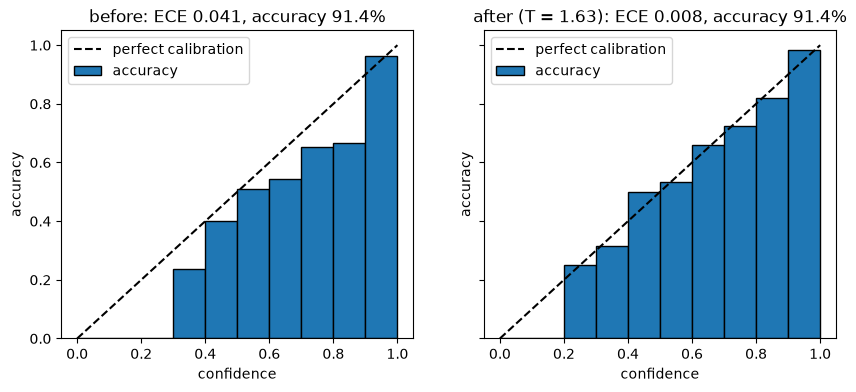

In [5]:
def reliability(network, ax, title):
    logits = network.predict(x_test, batch_size=1024, verbose=0)
    probs = keras.ops.convert_to_numpy(keras.ops.softmax(logits))
    confidence, correct = probs.max(-1), probs.argmax(-1) == y_test
    ece = keras_proba.metrics.ExpectedCalibrationError(num_bins=10, from_logits=True)
    ece.update_state(y_test, logits)
    bins = np.minimum((confidence * 10).astype(int), 9)
    accuracy = [correct[bins == b].mean() if np.any(bins == b) else 0 for b in range(10)]
    ax.bar((np.arange(10) + 0.5) / 10, accuracy, width=0.1, edgecolor="k", label="accuracy")
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.set(title=f"{title}: ECE {float(keras.ops.convert_to_numpy(ece.result())):.3f}, accuracy {correct.mean():.1%}",
           xlabel="confidence", ylabel="accuracy")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
reliability(model, axes[0], "before")
reliability(calibrated, axes[1], f"after (T = {temperature:.2f})")
plt.show()

## What we learned

- A network can be accurate and still overconfident: its confidence overstates how often it is
  right.
- Temperature scaling fixes this with one parameter, fitted on held-out data in a fraction of a
  second, without changing any prediction.
- [`ExpectedCalibrationError`](https://anas-rz.github.io/keras-proba/api/metrics/#keras_proba.metrics.ExpectedCalibrationError)
  and `BrierScore` measure calibration, also during training with `model.compile(metrics=...)`.